<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'

gray = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError(f"Could not read {IMG_PATH}")

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print("Image shape:", gray.shape)

Mounted at /content/drive
Image shape: (720, 1280)


In [2]:
def add_salt_pepper(img, d):
    out = img.copy()
    r = np.random.rand(*img.shape)
    out[r < d / 2] = 0
    out[(r >= d / 2) & (r < d)] = 255
    return out

def adaptive_median(img, s_init, s_max):
    out = img.copy()
    done = np.zeros(img.shape, bool)
    s = s_init
    while s <= s_max:
        ker = np.ones((s, s), np.uint8)
        zmin = cv2.erode(img, ker)
        zmax = cv2.dilate(img, ker)
        zmed = cv2.medianBlur(img, s)

        a_pass = (zmed > zmin) & (zmed < zmax)
        new = a_pass & ~done
        b_pass = (img > zmin) & (img < zmax)

        out[new & b_pass] = img[new & b_pass]
        out[new & ~b_pass] = zmed[new & ~b_pass]

        done |= a_pass
        last_med = zmed
        s += 2

    out[~done] = last_med[~done]
    return out

In [3]:
s_init = int(input("Initial window size (odd, e.g. 3): "))
s_max = int(input("Maximum window size Smax (odd, e.g. 7): "))
density = float(input("Salt and pepper noise density (0 to 1, e.g. 0.3): "))

if s_init % 2 == 0 or s_max % 2 == 0 or s_init > s_max:
    raise ValueError("Window sizes must be odd, with initial size <= Smax")

Initial window size (odd, e.g. 3): 5
Maximum window size Smax (odd, e.g. 7): 9
Salt and pepper noise density (0 to 1, e.g. 0.3): .5


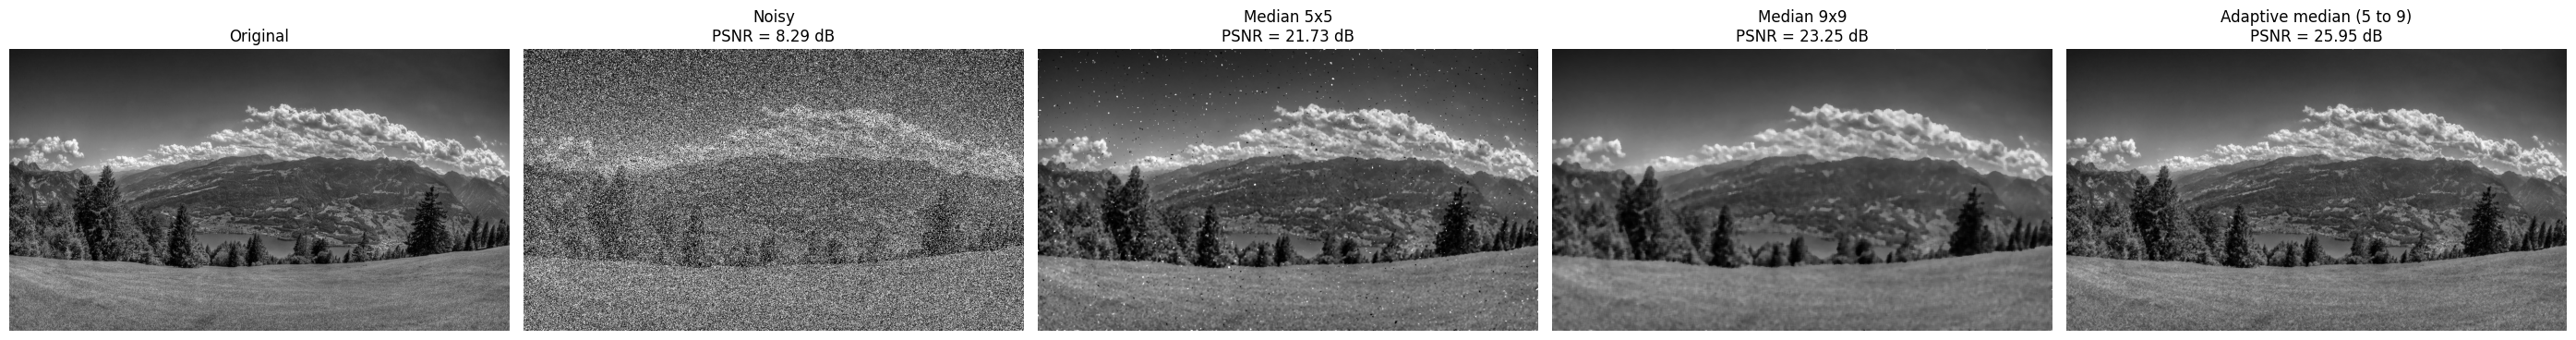

In [4]:
np.random.seed(0)

noisy = add_salt_pepper(gray, density)
med_init = cv2.medianBlur(noisy, s_init)
med_max = cv2.medianBlur(noisy, s_max)
adapt = adaptive_median(noisy, s_init, s_max)

fig, ax = plt.subplots(1, 5, figsize=(28, 6))
items = [(gray, 'Original'),
         (noisy, 'Noisy'),
         (med_init, f'Median {s_init}x{s_init}'),
         (med_max, f'Median {s_max}x{s_max}'),
         (adapt, f'Adaptive median ({s_init} to {s_max})')]

for a, (im, t) in zip(ax, items):
    a.imshow(im, cmap='gray', vmin=0, vmax=255)
    if t == 'Original':
        a.set_title(t)
    else:
        a.set_title(f'{t}\nPSNR = {psnr(gray, im):.2f} dB')
    a.axis('off')

plt.tight_layout()
plt.show()

In [5]:
print(f"Initial window = {s_init}, Smax = {s_max}\n")
print(f"{'Density':>8} | {'Noisy':>7} | {'Median init':>11} | {'Median Smax':>11} | {'Adaptive':>8}")
print("-" * 58)

for d in [0.1, 0.3, 0.5, 0.7]:
    n = add_salt_pepper(gray, d)
    print(f"{d:>8} | {psnr(gray, n):7.2f} | {psnr(gray, cv2.medianBlur(n, s_init)):11.2f} | "
          f"{psnr(gray, cv2.medianBlur(n, s_max)):11.2f} | {psnr(gray, adaptive_median(n, s_init, s_max)):8.2f}")

Initial window = 5, Smax = 9

 Density |   Noisy | Median init | Median Smax | Adaptive
----------------------------------------------------------
     0.1 |   15.27 |       24.66 |       23.69 |    31.71
     0.3 |   10.50 |       24.24 |       23.56 |    28.93
     0.5 |    8.27 |       21.74 |       23.27 |    25.95
     0.7 |    6.82 |       13.81 |       21.04 |    22.36


In [6]:
def otsu_threshold(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_t = mu[-1]

    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b2 = (mu_t * omega - mu) ** 2 / (omega * (1 - omega))

    sigma_b2 = np.nan_to_num(sigma_b2)
    best = np.flatnonzero(sigma_b2 == sigma_b2.max())
    return int(best.mean()), sigma_b2

Otsu threshold (mine) = 97
Otsu threshold (OpenCV) = 97


/tmp/ipykernel_6350/1138482444.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1].hist(gray.ravel(), 256, [0, 256])


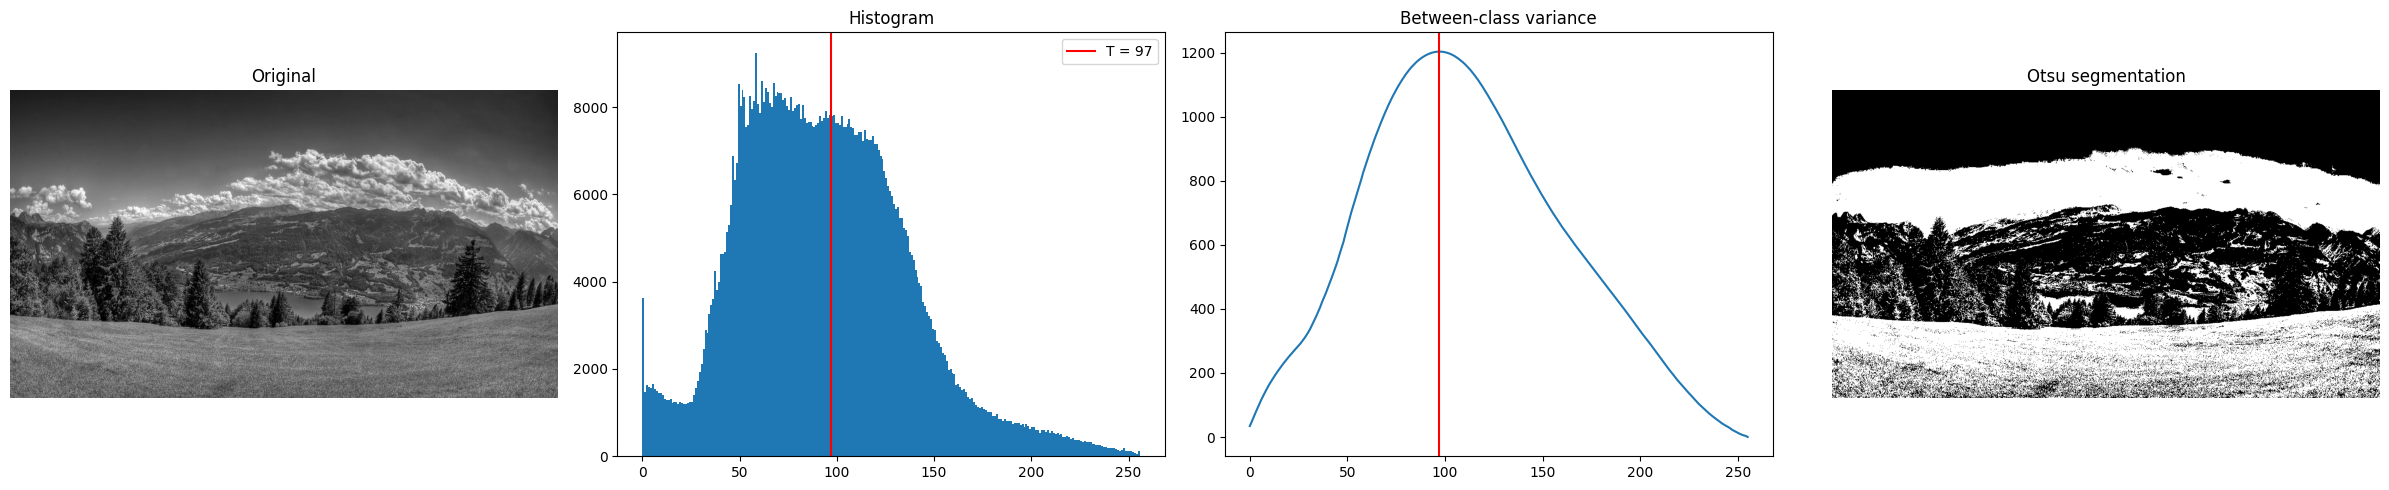

In [7]:
t, sigma_b2 = otsu_threshold(gray)
binary = np.where(gray > t, 255, 0).astype(np.uint8)

t_cv, binary_cv = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Otsu threshold (mine) = {t}")
print(f"Otsu threshold (OpenCV) = {int(t_cv)}")

fig, ax = plt.subplots(1, 4, figsize=(24, 5))
ax[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[0].axis('off')
ax[1].hist(gray.ravel(), 256, [0, 256])
ax[1].axvline(t, color='r', label=f'T = {t}')
ax[1].set_title('Histogram')
ax[1].legend()
ax[2].plot(sigma_b2)
ax[2].axvline(t, color='r')
ax[2].set_title('Between-class variance')
ax[3].imshow(binary, cmap='gray', vmin=0, vmax=255)
ax[3].set_title('Otsu segmentation')
ax[3].axis('off')
plt.tight_layout()
plt.show()